# Lab 14 (Week 3 — Lab 4): Recurrent Neural Networks & Sequence Data

Welcome to Lab 14! In this lab you will build a Recurrent Neural Network (using LSTM) for text classification — predicting whether a movie review is positive or negative.

**For detailed theory on RNNs, LSTMs, and sequence preparation, see the Lab 14 PDF and Learning Resources.**

This notebook focuses on the practical, hands-on workflow.

**Instructions:**
- Write your code between the `### YOUR CODE HERE ###` and `### END ###` markers.
- Run each cell with **Shift + Enter**.
- Compare your output with the **Expected Output** shown below each exercise where provided.
- Training on sequence data can take a few minutes per run — be patient.

## Getting the Dataset

This lab uses the IMDB Movie Reviews dataset, built directly into Keras — no download or upload needed. Reviews are already converted to sequences of word-index integers.

In [1]:
from tensorflow import keras
import numpy as np

vocab_size = 10000
(X_train, y_train), (X_test, y_test) = keras.datasets.imdb.load_data(num_words=vocab_size)

print("Training reviews:", len(X_train))
print("Test reviews:", len(X_test))
print("First review (word indices):", X_train[0][:20])
print("First review's label (0=negative, 1=positive):", y_train[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training reviews: 25000
Test reviews: 25000
First review (word indices): [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
First review's label (0=negative, 1=positive): 1


## Decoding a Review Back to Words

Just to see what the data actually represents, here's how to turn word indices back into readable text.

In [2]:
word_index = keras.datasets.imdb.get_word_index()
reverse_word_index = {value + 3: key for key, value in word_index.items()}
reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<UNK>"

def decode_review(encoded_review):
    return " ".join(reverse_word_index.get(i, "?") for i in encoded_review)

print(decode_review(X_train[0]))
print("\nLabel:", "Positive" if y_train[0] == 1 else "Negative")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also <UNK> to the two little boy's that played the <UNK> of norman and paul they were just brilliant children are often left out of the <UNK> list i think because the stars that play them all grown up are such a big profile for the whole film but these c

## Preparing the Data: Padding Sequences

Reviews vary in length, but the network needs a fixed input size. We'll pad/truncate every review to 200 words.

In [3]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

maxlen = 200
X_train_padded = pad_sequences(X_train, maxlen=maxlen)
X_test_padded = pad_sequences(X_test, maxlen=maxlen)

print("Padded shape:", X_train_padded.shape)
print("Example padded review:", X_train_padded[0][:20], "...")

Padded shape: (25000, 200)
Example padded review: [  5  25 100  43 838 112  50 670   2   9  35 480 284   5 150   4 172 112
 167   2] ...


## Example 1: Building an LSTM Model

In [4]:
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(maxlen,)),
    layers.Embedding(input_dim=vocab_size, output_dim=32),
    layers.LSTM(32),
    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 328,353 (1.25 MB)

 Trainable params: 328,353 (1.25 MB)

 Non-trainable params: 0 (0.00 B)

## Example 2: Compiling & Training

To keep training time reasonable, we'll train on a subset first.

In [5]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train_padded[:10000], y_train[:10000],
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 14s 96ms/step - accuracy: 0.6924 - loss: 0.5674 - val_accuracy: 0.7835 - val_loss: 0.4612
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 85ms/step - accuracy: 0.8780 - loss: 0.3098 - val_accuracy: 0.8425 - val_loss: 0.3676
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 22s 95ms/step - accuracy: 0.9354 - loss: 0.1874 - val_accuracy: 0.8615 - val_loss: 0.3476
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 93ms/step - accuracy: 0.9584 - loss: 0.1257 - val_accuracy: 0.8555 - val_loss: 0.4015
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 87ms/step - accuracy: 0.9749 - loss: 0.0878 - val_accuracy: 0.8560 - val_loss: 0.4413


## Example 3: Visualizing Training Progress

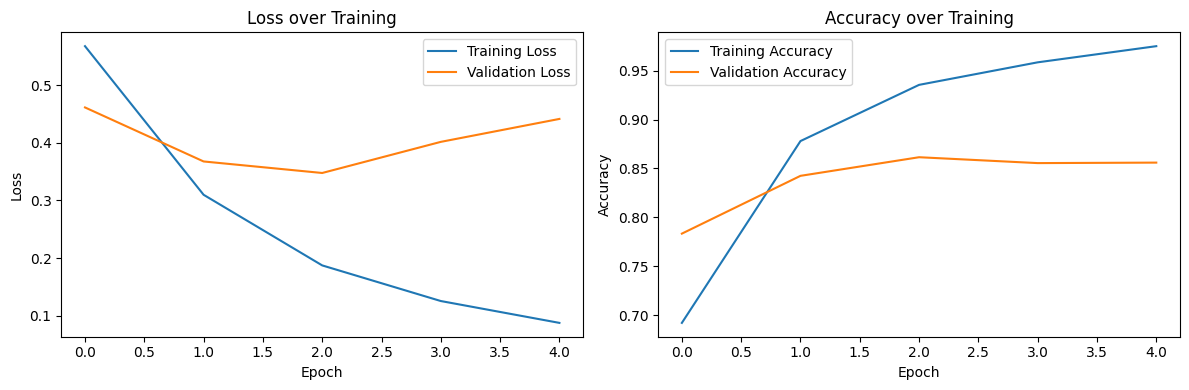

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss over Training")

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy over Training")

plt.tight_layout()
plt.show()

## Example 4: Evaluating and Predicting on New Reviews

In [7]:
test_loss, test_accuracy = model.evaluate(X_test_padded, y_test, verbose=0)
print(f"Test Accuracy: {test_accuracy:.4f}")

sample_predictions = model.predict(X_test_padded[:5], verbose=0)
for i in range(5):
    sentiment = "Positive" if sample_predictions[i][0] > 0.5 else "Negative"
    actual = "Positive" if y_test[i] == 1 else "Negative"
    print(f"Predicted: {sentiment} ({sample_predictions[i][0]:.2f}) | Actual: {actual}")

Test Accuracy: 0.8358
Predicted: Negative (0.17) | Actual: Negative
Predicted: Positive (1.00) | Actual: Positive
Predicted: Positive (0.99) | Actual: Positive
Predicted: Negative (0.02) | Actual: Negative
Predicted: Positive (1.00) | Actual: Positive


## Practice Exercise 1: Try a GRU Instead of LSTM

**Exercise:** Rebuild the model from Example 1, but replace `layers.LSTM(32)` with `layers.GRU(32)`. Train on the same 10,000-review subset for 5 epochs and compare test accuracy and training time to the LSTM version.

In [8]:
model_gru = None
test_accuracy_gru = None

### YOUR CODE HERE ###
model_gru = keras.Sequential([
    layers.Input(shape=(maxlen,)),
    layers.Embedding(input_dim=vocab_size, output_dim=32),
    layers.GRU(32),
    layers.Dense(1, activation="sigmoid")
])

model_gru.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_gru = model_gru.fit(
    X_train_padded[:10000],
    y_train[:10000],
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

test_loss_gru, test_accuracy_gru = model_gru.evaluate(
    X_test_padded, y_test, verbose=0
)

print("Test accuracy (LSTM):", test_accuracy)
### END ###

print("Test accuracy (GRU):", test_accuracy_gru)

Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 15s 101ms/step - accuracy: 0.6495 - loss: 0.6053 - val_accuracy: 0.8190 - val_loss: 0.4038
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 95ms/step - accuracy: 0.8562 - loss: 0.3360 - val_accuracy: 0.8485 - val_loss: 0.3560
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 22s 106ms/step - accuracy: 0.9227 - loss: 0.2066 - val_accuracy: 0.8510 - val_loss: 0.3939
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 15s 119ms/step - accuracy: 0.9452 - loss: 0.1547 - val_accuracy: 0.8305 - val_loss: 0.4725
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - accuracy: 0.9659 - loss: 0.1060 - val_accuracy: 0.8330 - val_loss: 0.4572
Test accuracy (LSTM): 0.8357599973678589
Test accuracy (GRU): 0.8237599730491638


## Practice Exercise 2: Changing Sequence Length

**Exercise:** Re-pad the reviews using `maxlen=100` instead of 200. Rebuild and retrain the LSTM model from Example 1 with this shorter sequence length. Compare test accuracy and training time to the original.

In [9]:
### YOUR CODE HERE ###
X_train_100 = pad_sequences(X_train, maxlen=100)
X_test_100 = pad_sequences(X_test, maxlen=100)

model_100 = keras.Sequential([
    layers.Input(shape=(100,)),
    layers.Embedding(input_dim=vocab_size, output_dim=32),
    layers.LSTM(32),
    layers.Dense(1, activation="sigmoid")
])

model_100.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_100 = model_100.fit(
    X_train_100[:10000],
    y_train[:10000],
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

loss_100, accuracy_100 = model_100.evaluate(
    X_test_100, y_test, verbose=0
)

print("Test accuracy, length 200:", test_accuracy)
print("Test accuracy, length 100:", accuracy_100)
### END ###

Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 43ms/step - accuracy: 0.6926 - loss: 0.5798 - val_accuracy: 0.8195 - val_loss: 0.4215
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 61ms/step - accuracy: 0.8724 - loss: 0.3120 - val_accuracy: 0.8460 - val_loss: 0.3660
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 10s 61ms/step - accuracy: 0.9304 - loss: 0.1946 - val_accuracy: 0.8255 - val_loss: 0.3859
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 44ms/step - accuracy: 0.9616 - loss: 0.1257 - val_accuracy: 0.8160 - val_loss: 0.4332
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.9701 - loss: 0.0876 - val_accuracy: 0.8170 - val_loss: 0.5508
Test accuracy, length 200: 0.8357599973678589
Test accuracy, length 100: 0.8180800080299377


Shorter sequences give the model fewer words to process, which can reduce training time. However, they can also remove information needed to understand a review. I compared the actual accuracy and execution times to see how this affected my models.

## Practice Exercise 3: Predicting Your Own Review

**Exercise:** Write your own short movie review as a Python string (2-3 sentences). Convert it to word indices using the `word_index` dictionary from earlier (map each word to its index, using 2 for unknown words, then add 3 to match the dataset's offset), pad it to `maxlen=200`, and predict its sentiment using your trained model.

In [10]:
my_review = "This movie was absolutely wonderful and I loved every minute of it"

### YOUR CODE HERE ###
words = my_review.lower().replace(".", "").split()

encoded_review = [
    word_index.get(word, -1) + 3
    for word in words
]

encoded_review = [
    index if index < vocab_size else 2
    for index in encoded_review
]

encoded_review = [1] + encoded_review

my_review_padded = pad_sequences(
    [encoded_review],
    maxlen=200
)

my_prediction = model.predict(my_review_padded, verbose=0)

sentiment = (
    "Positive" if my_prediction[0][0] > 0.5 else "Negative"
)

print("Review:", my_review)
print("Predicted sentiment:", sentiment)
print("Positive sentiment score:", my_prediction[0][0])
### END ###

Review: This movie was absolutely wonderful and I loved every minute of it
Predicted sentiment: Positive
Positive sentiment score: 0.8423784


## Lab Tasks

Complete the following in this notebook, below this cell.

1. **Build & Train Your Own Model**: Design your own architecture (try stacking 2 LSTM layers, or changing the embedding/LSTM unit sizes). Train on at least 10,000 reviews and report test accuracy.
2. **RNN Type Comparison**: Train the same architecture using SimpleRNN, GRU, and LSTM (keeping other settings constant). Create a comparison table of test accuracy and approximate training time for each.
3. **Sequence Length Experiment**: Try 3 different `maxlen` values (e.g., 50, 100, 200) with your best architecture. Report test accuracy for each and discuss the trade-off between sequence length and training time.
4. **Error Analysis**: Find 3 reviews in the test set that your best model misclassified. Print the decoded text (using `decode_review`) and the predicted vs. actual sentiment for each. In a markdown cell, speculate on why the model might have gotten these wrong.
5. **Reflection**: In a markdown cell, write 3-4 sentences on how processing sequence data (text) with an RNN differs from processing image data with a CNN (Lab 13), and why each architecture fits its respective data type.

In [11]:
# Task 1

def build_review_model(recurrent_type, sequence_length):
    if recurrent_type == "SimpleRNN":
        recurrent_layer = layers.SimpleRNN(64)
    elif recurrent_type == "GRU":
        recurrent_layer = layers.GRU(64)
    else:
        recurrent_layer = layers.LSTM(64)

    review_model = keras.Sequential([
        layers.Input(shape=(sequence_length,)),
        layers.Embedding(
            input_dim=vocab_size,
            output_dim=64
        ),
        recurrent_layer,
        layers.Dense(1, activation="sigmoid")
    ])

    review_model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return review_model

In [12]:
my_model = build_review_model("LSTM", 200)

my_history = my_model.fit(
    X_train_padded[:12500],
    y_train[:12500],
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

my_loss, my_accuracy = my_model.evaluate(
    X_test_padded, y_test, verbose=0
)

print("My LSTM test accuracy:", my_accuracy)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 27s 161ms/step - accuracy: 0.6955 - loss: 0.5698 - val_accuracy: 0.8116 - val_loss: 0.4303
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 40s 155ms/step - accuracy: 0.8805 - loss: 0.2994 - val_accuracy: 0.8476 - val_loss: 0.3665
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 40s 149ms/step - accuracy: 0.9262 - loss: 0.2054 - val_accuracy: 0.8400 - val_loss: 0.4226
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 42s 158ms/step - accuracy: 0.9502 - loss: 0.1437 - val_accuracy: 0.8300 - val_loss: 0.5491
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 24s 152ms/step - accuracy: 0.9627 - loss: 0.1068 - val_accuracy: 0.8544 - val_loss: 0.5049
My LSTM test accuracy: 0.8448799848556519


I used an embedding size of 64 and an LSTM with 64 units. I kept the sigmoid output because there are two sentiment classes. The model used 10,000 reviews for weight updates and 2,500 for validation.

In [13]:
# Task 2

import time
import pandas as pd

models = {}
histories = {}
accuracies = {}
cpu_times = {}

for recurrent_type in ["SimpleRNN", "GRU", "LSTM"]:
    current_model = build_review_model(recurrent_type, 200)

    start = time.process_time()

    current_history = current_model.fit(
        X_train_padded[:12500],
        y_train[:12500],
        epochs=5,
        batch_size=64,
        validation_split=0.2,
        verbose=1
    )

    cpu_seconds = time.process_time() - start

    current_loss, current_accuracy = current_model.evaluate(
        X_test_padded, y_test, verbose=0
    )

    models[recurrent_type] = current_model
    histories[recurrent_type] = current_history
    accuracies[recurrent_type] = current_accuracy
    cpu_times[recurrent_type] = cpu_seconds

comparison = pd.DataFrame({
    "Model": ["SimpleRNN", "GRU", "LSTM"],
    "Test Accuracy": [
        accuracies["SimpleRNN"],
        accuracies["GRU"],
        accuracies["LSTM"]
    ],
    "Training CPU Seconds": [
        cpu_times["SimpleRNN"],
        cpu_times["GRU"],
        cpu_times["LSTM"]
    ]
})

print(comparison)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 14s 77ms/step - accuracy: 0.5854 - loss: 0.6619 - val_accuracy: 0.7200 - val_loss: 0.5633
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 20s 76ms/step - accuracy: 0.8177 - loss: 0.4165 - val_accuracy: 0.7544 - val_loss: 0.5341
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 12s 75ms/step - accuracy: 0.9350 - loss: 0.1784 - val_accuracy: 0.8056 - val_loss: 0.4933
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 12s 76ms/step - accuracy: 0.9872 - loss: 0.0486 - val_accuracy: 0.7884 - val_loss: 0.5992
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 20s 74ms/step - accuracy: 0.9991 - loss: 0.0097 - val_accuracy: 0.7788 - val_loss: 0.6532
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 34s 205ms/step - accuracy: 0.6588 - loss: 0.6035 - val_accuracy: 0.7888 - val_loss: 0.4615
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 30s 189ms/step - accuracy: 0.8694 - loss: 0.3154 - val_accuracy: 0.8424 - val_loss: 0.3767
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 31s 196ms/step - accuracy: 0.9307 - loss: 0.1875 - val_a

In [14]:
if (
    accuracies["SimpleRNN"] >= accuracies["GRU"]
    and accuracies["SimpleRNN"] >= accuracies["LSTM"]
):
    best_type = "SimpleRNN"

elif accuracies["GRU"] >= accuracies["LSTM"]:
    best_type = "GRU"

else:
    best_type = "LSTM"

print("Selected recurrent type:", best_type)

Selected recurrent type: LSTM


In [15]:
# Task 3

length_models = {}
length_accuracies = {}
length_cpu_times = {}

for sequence_length in [50, 100, 200]:
    train_padded = pad_sequences(
        X_train,
        maxlen=sequence_length
    )
    test_padded = pad_sequences(
        X_test,
        maxlen=sequence_length
    )

    length_model = build_review_model(
        best_type,
        sequence_length
    )

    start = time.process_time()

    length_model.fit(
        train_padded[:12500],
        y_train[:12500],
        epochs=5,
        batch_size=64,
        validation_split=0.2,
        verbose=1
    )

    cpu_seconds = time.process_time() - start

    length_loss, length_accuracy = length_model.evaluate(
        test_padded, y_test, verbose=0
    )

    length_models[sequence_length] = length_model
    length_accuracies[sequence_length] = length_accuracy
    length_cpu_times[sequence_length] = cpu_seconds

length_comparison = pd.DataFrame({
    "Sequence Length": [50, 100, 200],
    "Test Accuracy": [
        length_accuracies[50],
        length_accuracies[100],
        length_accuracies[200]
    ],
    "Training CPU Seconds": [
        length_cpu_times[50],
        length_cpu_times[100],
        length_cpu_times[200]
    ]
})

print(length_comparison)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - accuracy: 0.7098 - loss: 0.5434 - val_accuracy: 0.7880 - val_loss: 0.4467
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 8s 53ms/step - accuracy: 0.8637 - loss: 0.3235 - val_accuracy: 0.7948 - val_loss: 0.4452
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 7s 43ms/step - accuracy: 0.9140 - loss: 0.2223 - val_accuracy: 0.7936 - val_loss: 0.5172
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - accuracy: 0.9440 - loss: 0.1549 - val_accuracy: 0.7828 - val_loss: 0.6449
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 8s 52ms/step - accuracy: 0.9688 - loss: 0.0923 - val_accuracy: 0.7760 - val_loss: 0.8119
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 16s 86ms/step - accuracy: 0.7324 - loss: 0.5162 - val_accuracy: 0.8316 - val_loss: 0.3970
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 13s 85ms/step - accuracy: 0.8891 - loss: 0.2767 - val_accuracy: 0.8264 - val_loss: 0.3863
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 13s 84ms/step - accuracy: 0.9368 - loss: 0.1810 - val_accurac

I compared sequence lengths of 50, 100 and 200 using the same recurrent architecture and training settings. Test accuracy increased from 77.36% at length 50 to 81.21% at length 100 and 83.94% at length 200. Training CPU time also increased from 61.85 to 108.91 and 204.26 seconds respectively. Length 200 gave the best accuracy in this run, while length 100 offered a quicker option with lower accuracy.

In [16]:
# Task 4

if (
    length_accuracies[50] >= length_accuracies[100]
    and length_accuracies[50] >= length_accuracies[200]
):
    best_length = 50

elif length_accuracies[100] >= length_accuracies[200]:
    best_length = 100

else:
    best_length = 200

best_model = length_models[best_length]

best_test_padded = pad_sequences(
    X_test,
    maxlen=best_length
)

best_probabilities = best_model.predict(
    best_test_padded,
    verbose=0
)

best_labels = best_probabilities[:, 0] > 0.5

shown = 0

for i in range(len(y_test)):
    if best_labels[i] != y_test[i] and shown < 3:
        print("\nReview:", shown + 1)

        print(
            "Text seen by the model:",
            decode_review(best_test_padded[i])
        )

        predicted = (
            "Positive" if best_labels[i] else "Negative"
        )
        actual = (
            "Positive" if y_test[i] == 1 else "Negative"
        )

        print("Predicted:", predicted)
        print("Actual:", actual)
        print("Positive score:", best_probabilities[i][0])

        shown = shown + 1



Review: 1
Text seen by the model: <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <START> hollywood had a long love affair with bogus <UNK> nights tales but few of these products have stood the test of time the most memorable were the jon hall maria <UNK> films which have long since become camp this one is filled with dubbed songs <UNK> <UNK> and slapstick it's a truly crop of corn and pretty near <UNK> today it was nominated for its imaginative special effects which are almost <UNK> in this day and age <UNK> mainly of trick photography the only outstanding positive feature which survives is its beautiful color and clarity sad to say of the ma

The first two reviews were negative, but the model predicted them as positive with scores of about 1.00 and 0.87. The third review was positive, but its positive score was only 0.32, so it was classified as negative. Unknown words and the 200-token limit may have removed useful information, but I would need to read the full displayed reviews to understand these mistakes better.

_Write your Task 5 reflection here._

The CNN in Lab 13 learnt local patterns across image pixels using filters and pooling. In this lab, the recurrent model processes words in order and carries information through a hidden state. This suits text because the meaning of a word can depend on the words before it. The embedding layer also lets the model learn numerical representations of words instead of treating their vocabulary indices as measurements.